### Instalação e importações de bibliotecas

In [1]:
# Instala as bibliotecas
%pip install -q transformers torchaudio

In [22]:
import torch, torchaudio, matplotlib.pyplot as plt
from IPython.display import Audio, display
import urllib.request, torch.nn.functional as F
from transformers import Wav2Vec2ForCTC, Wav2Vec2Processor

### Carrega modelo

In [2]:
# Carrega o modelo-alvo

device = "cuda" if torch.cuda.is_available() else "cpu"

processor = Wav2Vec2Processor.from_pretrained("facebook/wav2vec2-base-960h")
modelo = Wav2Vec2ForCTC.from_pretrained("facebook/wav2vec2-base-960h").to(device).eval()

preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.60k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/163 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/291 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/212 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForCTC LOAD REPORT from: facebook/wav2vec2-base-960h
Key                        | Status  | 
---------------------------+---------+-
wav2vec2.masked_spec_embed | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


### Leitura audio original

In [5]:
url = "https://download.pytorch.org/torchaudio/tutorial-assets/Lab41-SRI-VOiCES-src-sp0307-ch127535-sg0042.wav"
caminho = "/content/clean.wav"
urllib.request.urlretrieve(url, caminho)

sinal, sr = torchaudio.load(caminho)
sinal = sinal.mean(dim=0)
if sr != 16000:
    sinal = torchaudio.functional.resample(sinal, sr, 16000)

def transcreve(onda):
    x = processor(onda.detach().cpu().numpy(), sampling_rate=16000, return_tensors="pt").input_values.to(device) # processador espera formato numpy
    with torch.no_grad():
        logits = modelo(x).logits
    return processor.batch_decode(logits.argmax(-1))[0]

display(Audio(sinal.numpy(), rate=16000))
print("Transcricao do audio limpo:")
print(transcreve(sinal))

Transcricao do audio limpo:
I HAD THAT CURIOSITY BESIDE ME AT THIS MOMENT


### Geração ataque não direcionado

In [6]:
# hiperparametros do ataque
eps = 0.004
alpha = 0.0005
iteracoes = 30

texto_limpo = transcreve(sinal)
labels = processor.tokenizer(texto_limpo, return_tensors="pt").input_ids.to(device)

# normalizacao
def forward_logits(wave, labels=None):
    iv = (wave - wave.mean()) / torch.sqrt(wave.var() + 1e-7)
    return modelo(iv.unsqueeze(0), labels=labels)

x_orig = sinal.clone().to(device)
x_adv = x_orig.clone()

for i in range(iteracoes):
    x_adv = x_adv.detach().requires_grad_(True)
    loss = forward_logits(x_adv, labels).loss      # CTC loss da transcricao correta
    grad = torch.autograd.grad(loss, x_adv)[0]
    x_adv = x_adv + alpha * grad.sign()            # SOBE a loss
    x_adv = torch.max(torch.min(x_adv, x_orig + eps), x_orig - eps)  # bola L-inf
    x_adv = x_adv.clamp(-1, 1)

x_adv = x_adv.detach()

# resultado
pert = (x_adv - x_orig)
snr = 10 * torch.log10((x_orig**2).mean() / (pert**2).mean())
print("Limpo:      ", texto_limpo)
print("Adversarial:", transcreve(x_adv))
print(f"perturbacao max: {pert.abs().max():.4f} | SNR: {snr:.1f} dB")

Limpo:       I HAD THAT CURIOSITY BESIDE ME AT THIS MOMENT
Adversarial: WHY HAVE THAT CURIOSITY BESIDE ME AT THIS MULLET
perturbacao max: 0.0040 | SNR: 33.4 dB


Adversarial:


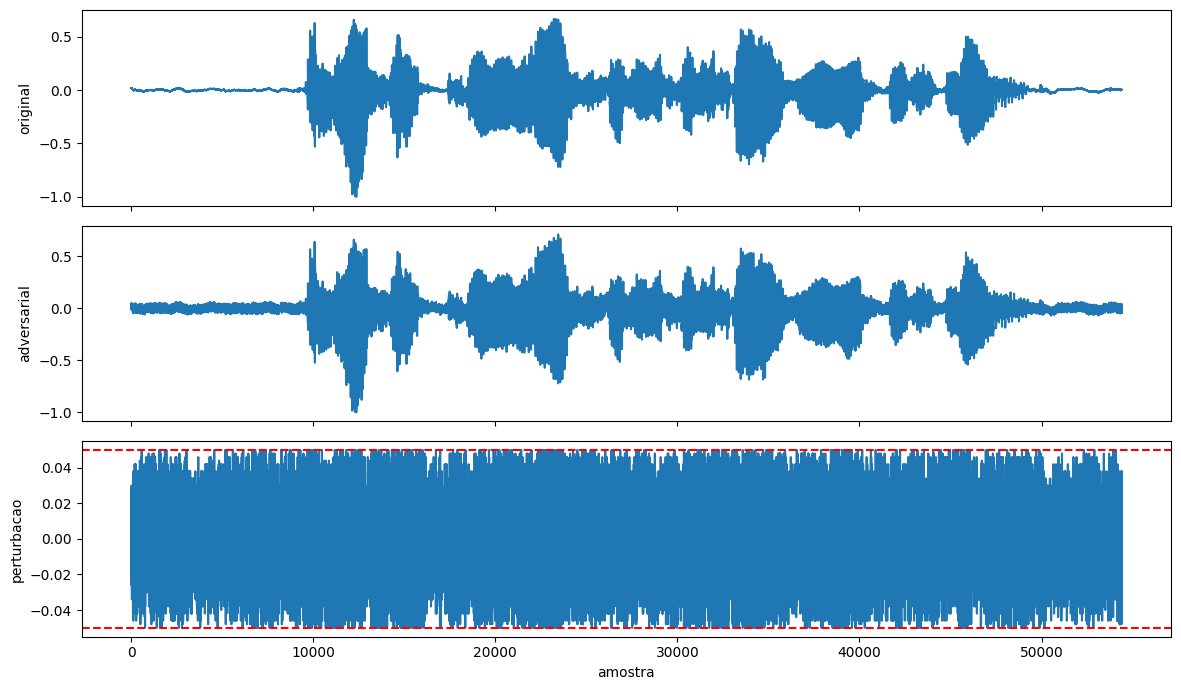

In [20]:
# Executa e exibi sinal de audio
adv_signal = x_adv.detach().cpu().numpy()
x0 = x_orig.detach().cpu().numpy()
print("Adversarial:"); display(Audio(adv_signal, rate=16000))

torchaudio.save("/content/adv_nao_direcionado.wav", x_adv.detach().cpu().unsqueeze(0), 16000)

pert = adv_signal - x0
fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
ax[0].plot(x0);         ax[0].set_ylabel("original")
ax[1].plot(adv_signal); ax[1].set_ylabel("adversarial")
ax[2].plot(pert);       ax[2].set_ylabel("perturbacao")
lim = abs(pert).max()
ax[2].axhline(lim, color="r", ls="--"); ax[2].axhline(-lim, color="r", ls="--")
ax[2].set_xlabel("amostra")
plt.tight_layout(); plt.show()

In [17]:
# Ataque adversarial DIRECIONADO (PGD em direcao a um texto-alvo)
alvo_texto = "HELLO WORLD"
alvo_labels = processor.tokenizer(alvo_texto, return_tensors="pt").input_ids.to(device)

eps = 0.05           # raio maior (direcionado precisa de mais perturbacao)
alpha = 0.002        # passo
iteracoes = 200

x_orig = sinal.clone().to(device)
x_adv = x_orig.clone()

for i in range(iteracoes):
    x_adv = x_adv.detach().requires_grad_(True)
    loss = forward_logits(x_adv, alvo_labels).loss     # CTC loss em relacao ao ALVO
    grad = torch.autograd.grad(loss, x_adv)[0]
    x_adv = x_adv - alpha * grad.sign()                # DESCE a loss (aproxima do alvo)
    x_adv = torch.max(torch.min(x_adv, x_orig + eps), x_orig - eps)
    x_adv = x_adv.clamp(-1, 1)

    if i % 10 == 0 or i == iteracoes - 1:
        atual = transcreve(x_adv.detach())
        print(f"iter {i} | {atual}")
        if atual == alvo_texto:
            print("alvo atingido!")
            break

x_adv_dir = x_adv.detach()
pert = x_adv_dir - x_orig
snr = 10 * torch.log10((x_orig**2).mean() / (pert**2).mean())
print()

print("Alvo:       ", alvo_texto)
print("Adversarial:", transcreve(x_adv_dir))
print(f"perturbacao max: {pert.abs().max():.4f} | SNR: {snr:.1f} dB")

iter 0 | I HAVE THAT CURIOSITY BESIDE ME AT THIS MOMENT
iter 10 | A HANDAN CURIOSITY BESIDE ME THIS MONANT
iter 20 | I HAD NAT CURIOSITY BESIE ME THIS MONENT
iter 30 | I HED CUIOS ME WARLD
iter 40 | HCWORLD
iter 50 | HECUMWORLD
iter 60 | HELDWORLD
iter 70 | HEWORLD
iter 80 | HELDOWORLD
iter 90 | HELLOWORLD
iter 100 | HELLO WORLD
alvo atingido!

Original:    I HAD THAT CURIOSITY BESIDE ME AT THIS MOMENT
Alvo:        HELLO WORLD
Adversarial: HELLO WORLD
perturbacao max: 0.0500 | SNR: 15.5 dB


Adversarial (alvo):


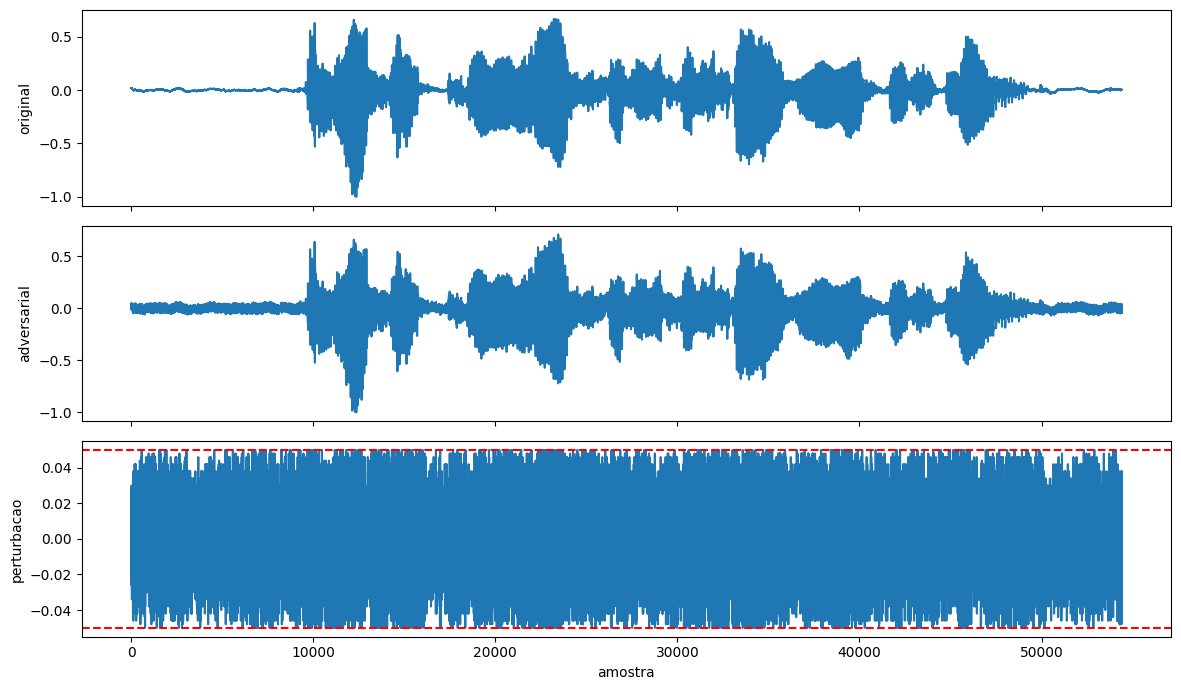

In [21]:
# Executa e exibi sinal de audio
adv_dir_signal = x_adv_dir.detach().cpu().numpy()
x0 = x_orig.detach().cpu().numpy()

print("Adversarial (alvo):"); display(Audio(adv_dir_signal, rate=16000))

torchaudio.save("/content/adv_direcionado.wav", x_adv_dir.detach().cpu().unsqueeze(0), 16000)

pert = adv_dir_signal - x0
fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
ax[0].plot(x0); ax[0].set_ylabel("original")
ax[1].plot(adv_dir_signal); ax[1].set_ylabel("adversarial")
ax[2].plot(pert); ax[2].set_ylabel("perturbacao")
lim = abs(pert).max()
ax[2].axhline(lim, color="r", ls="--"); ax[2].axhline(-lim, color="r", ls="--")
ax[2].set_xlabel("amostra")
plt.tight_layout(); plt.show()